# Validation méthode estimation exogène coopérative

Vérifier le fonctionnement de Agent.estimate_exogenous() sur les données réelles de Toulouse: coopération entre agents hétérogènes (température, humidité, pression) via l'Environment (ask_weights), et combinaison par histogramme (Estimator.combine_estimates).

Identique au notebook de la méthode par historique : la valeur réelle à t n'est jamais utilisée pour l'estimation (filtre strict before=t).

In [2]:
# Uncomment if dependencies are not installed
# %pip install -r requirements.txt

In [3]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

from datetime import datetime, timedelta
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from hybridiot import MeteoDataset, Agent, Environment, Estimator

In [4]:
# Chargement du dataset
ds = MeteoDataset.from_csv('../data/toulouse_meteo_2020(35.000).csv')
print(ds.describe())

  Sampling frequency detected: 15 min
MeteoDataset 'toulouse_meteo_2020(35.000)'
  Source      : ../data/toulouse_meteo_2020(35.000).csv
  Sensors     : 6 stations
  Data types  : ['temperature', 'humidite', 'pression', 'pluie', 'pluie_intensite_max']
  Tensor      : (5, 35136, 6)  (n_types × n_timesteps × n_sensors)
  Timesteps   : 35136 (every 15 min)
  Time range  : 2020-01-01 00:00:00+00:00 -> 2020-12-31 23:45:00+00:00
  NaN rate    : 1.87%


Pour la coopération exogène, il faut des agents de types différents. On crée, pour chaque station, un agent par type de donnée (température, humidité, pression), tous enregistrés dans l'environnement global.

L'agent cible (celui qui estime) est un agent température; ses collaborateurs potentiels sont tous les agents non-température (sélectionnés par l'Environment, jamais par l'agent lui-même).

In [5]:
DATA_TYPES = ['temperature', 'humidite', 'pression']

env = Environment(base_dataset=ds)

for station in ds.sensors:
    for dtype in DATA_TYPES:
        agent = Agent(
            id        = station.id,
            position  = station.position,
            data_type = dtype,
            frequency = 15,
        )
        env.register_agent(agent)
        agent.load_from_dataset(ds)

print(env)
for a in env.agents:
    print(f'  {a.id}  [{a.data_type}]  {len(a.dataset)} valeurs')

Environment(agents=18, base_dataset='toulouse_meteo_2020(35.000)')
  Castelginest Ecole  [temperature]  35136 valeurs
  Castelginest Ecole  [humidite]  35136 valeurs
  Castelginest Ecole  [pression]  35136 valeurs
  Colomiers Za Perget  [temperature]  35136 valeurs
  Colomiers Za Perget  [humidite]  35136 valeurs
  Colomiers Za Perget  [pression]  35136 valeurs
  Mondouzil Mairie  [temperature]  35136 valeurs
  Mondouzil Mairie  [humidite]  35136 valeurs
  Mondouzil Mairie  [pression]  35136 valeurs
  Toulouse Avenue De Grande Bretagne  [temperature]  35136 valeurs
  Toulouse Avenue De Grande Bretagne  [humidite]  35136 valeurs
  Toulouse Avenue De Grande Bretagne  [pression]  35136 valeurs
  Toulouse Basso Cambo  [temperature]  35136 valeurs
  Toulouse Basso Cambo  [humidite]  35136 valeurs
  Toulouse Basso Cambo  [pression]  35136 valeurs
  Toulouse Nakache Archive2019  [temperature]  35136 valeurs
  Toulouse Nakache Archive2019  [humidite]  35136 valeurs
  Toulouse Nakache Archive20

In [6]:
# Agent cible: un agent température
TARGET_STATION = ds.sensors[0].id   # adapter si besoin
agent = env.get_agent(TARGET_STATION, data_type='temperature')
print('Agent cible :', agent.id, f'[{agent.data_type}]')
print(f'Dataset local : {len(agent.dataset)} valeurs')

# Vérification: les collaborateurs hétérogènes existent
hetero = env.get_neighbours(agent, same_data_type=False)
print('Collaborateurs hétérogènes sélectionnables :', [(a.id, a.data_type) for a in hetero])

Agent cible : Castelginest Ecole [temperature]
Dataset local : 35136 valeurs
Collaborateurs hétérogènes sélectionnables : [('Mondouzil Mairie', 'humidite'), ('Toulouse Basso Cambo', 'pression'), ('Colomiers Za Perget', 'pression'), ('Toulouse Avenue De Grande Bretagne', 'pression'), ('Toulouse Nakache Archive2019', 'pression')]


## 1. Cas nominal: une estimation ponctuelle

On choisit un timestamp aux 3/4 du dataset, on estime avec la méthode exogène, et on compare à la valeur réelle et à l'estimation endogène seule.

In [28]:
# Timestamp cible: aux 3/4 du dataset
idx_target = (len(agent.dataset) * 3) // 4
ts_target, real_value = agent.dataset[idx_target]

est_exo = agent.estimate_exogenous(ts_target)
est_end = agent.estimate_from_history(ts_target)

print(f'Timestamp cible      : {ts_target}')
print(f'Valeur réelle        : {real_value:.2f}')
print(f'Estimation exogène   : {est_exo:.2f}  (erreur : {abs(est_exo - real_value):.2f})')
print(f'Estimation endogène  : {est_end:.2f}  (erreur : {abs(est_end - real_value):.2f})')

Timestamp cible      : 2020-10-01 12:00:00+00:00
Valeur réelle        : 18.00
Estimation exogène   : 17.16  (erreur : 0.84)
Estimation endogène  : 18.23  (erreur : 0.23)


## 2. Évaluation systématique: MAE sur N timestamps

Trois estimateurs comparés sur les mêmes timestamps :
- exogène: coopération hétérogène + histogramme
- endogène: historique seul (méthode 1)
- persistance: dernière valeur perçue (baseline, w_t = 0)

La sélection des collaborateurs par get_neighbours étant aléatoire pondérée, les résultats exogènes peuvent varier légèrement d'une exécution à l'autre.

La méthode exogène est plus coûteuse (chaque collaborateur reconstruit des fenêtres aux instants Sigma): si la cellule est trop lente, réduire N.

In [29]:
N = 50
half = len(agent.dataset) // 2
step = (len(agent.dataset) - half) // N
indices = range(half, len(agent.dataset), step)

errors_exo, errors_end, errors_persistence = [], [], []
results = []  # (ts, real, est_exo) pour le graphique
skipped = 0

for idx in indices:
    ts, real = agent.dataset[idx]
    if real is None or (isinstance(real, float) and np.isnan(real)):
        skipped += 1
        continue  # pas de vérité terrain à ce timestamp

    est_exo = agent.estimate_exogenous(ts)
    est_end = agent.estimate_from_history(ts)
    if est_exo is None or est_end is None:
        skipped += 1
        continue

    valid_before = agent._get_valid_values(before=ts)
    persistence = valid_before[-1]

    errors_exo.append(abs(est_exo - real))
    errors_end.append(abs(est_end - real))
    errors_persistence.append(abs(persistence - real))
    results.append((ts, real, est_exo))

mae_exo = np.mean(errors_exo)
mae_end = np.mean(errors_end)
mae_persistence = np.mean(errors_persistence)

print(f'Estimations évaluées : {len(errors_exo)} (ignorées : {skipped})')
print(f'MAE exogène     : {mae_exo:.3f}')
print(f'MAE endogène    : {mae_end:.3f}')
print(f'MAE persistance : {mae_persistence:.3f}')
print(f'Exogène vs persistance : {(1 - mae_exo/mae_persistence)*100:+.1f}%')
print(f'Exogène vs endogène    : {(1 - mae_exo/mae_end)*100:+.1f}%')

Estimations évaluées : 51 (ignorées : 0)
MAE exogène     : 0.422
MAE endogène    : 0.175
MAE persistance : 0.200
Exogène vs persistance : -111.2%
Exogène vs endogène    : -142.1%


## 3. Graphique série temporelle réel vs estimé

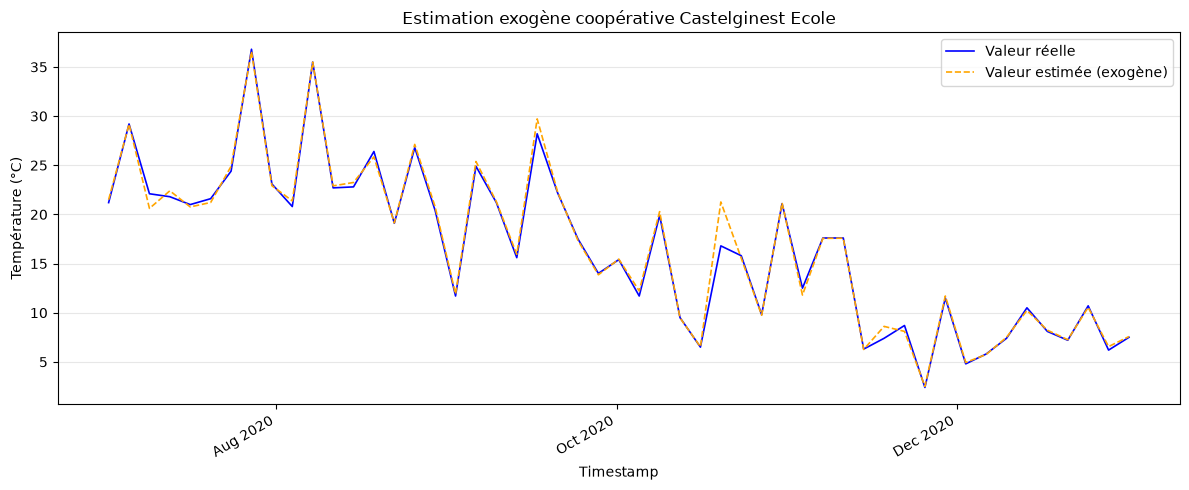

In [9]:
fig, axes = plt.subplots(1, 1, figsize=(12, 5))

plot_ts, plot_real, plot_est = zip(*results)

axes.plot(plot_ts, plot_real, label='Valeur réelle', color='blue', linewidth=1.2)
axes.plot(plot_ts, plot_est, label='Valeur estimée (exogène)', color='orange', linewidth=1.2, linestyle='--')
axes.set_title(f'Estimation exogène coopérative {agent.id}')
axes.set_xlabel('Timestamp')
axes.set_ylabel('Température (°C)')
axes.legend()
axes.grid(axis='y', alpha=0.3)
axes.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.setp(axes.xaxis.get_majorticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.show()

## 4. Cas limites

- historique insuffisant = None (l'exogène contient l'endogène: sans historique, pas d'E_end ni de Sigma)
- agent sans environnement = repli sur l'estimation endogène
- aucun collaborateur hétérogène = repli sur l'estimation endogène

In [10]:
t0 = datetime(2020, 7, 1, 12, 0)

# Cas 1: historique insuffisant
agent_empty = Agent(id='empty_station', data_type='temperature', position=(0, 0))
result = agent_empty.estimate_exogenous(t0)
print('Historique insuffisant :', result)

# Cas 2: agent isolé (sans environnement)
agent_alone = Agent(id='alone_station', data_type='temperature', position=(0, 0))
for i in range(20):
    agent_alone.add_value(value=20.0 + 0.1*i, timestamp=t0 + timedelta(minutes=15*i))
ts_test = t0 + timedelta(minutes=15*20)

exo = agent_alone.estimate_exogenous(ts_test)
end = agent_alone.estimate_from_history(ts_test)
print(f'Agent isolé : exogène = {exo:.2f}, endogène = {end:.2f}')

# Cas 3: aucun collaborateur hétérogène 
env_homo = Environment(base_dataset=None)
env_homo.register_agent(agent_alone)   # seul agent du système

exo = agent_alone.estimate_exogenous(ts_test)
print(f'Aucun collaborateur : exogène = {exo:.2f}, endogène = {end:.2f}')

print('\nTous les cas limites gérés proprement (None ou repli endogène).')

Historique insuffisant : None
Agent isolé : exogène = 22.00, endogène = 22.00
Aucun collaborateur : exogène = 22.00, endogène = 22.00

Tous les cas limites gérés proprement (None ou repli endogène).
